In [1]:
# Install packages in the original Google Colab environment.
!pip install geopandas -q
!pip install arviz==0.23.0 -q
!pip install pymc -q
!pip install nutpie -q
!pip install numpyro -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.9/444.9 kB 2.1 MB/s eta 0:00:00


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Import geospatial, numerical, Bayesian modeling, and diagnostic libraries.
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
import libpysal.weights as lw
from libpysal.weights import Queen

import os
#import warnings
import arviz as az
import pymc as pm
import pytensor.tensor as pt

import networkx as nx
import nutpie

from sklearn.preprocessing import StandardScaler

from esda.moran import Moran

from scipy import sparse
from scipy.linalg import solve
from scipy.sparse.linalg import spsolve
#warnings.filterwarnings("ignore")

In [4]:
# Optional environment version-reporting block retained as provided.
"""

import sys

# Python version
print(f"Python Version: {sys.version.split(' ')[0]}")

# Imported libraries versions
print("\nImported Library Versions:")
for module_name in sorted(sys.modules.keys()):
    if any(keyword in module_name for keyword in ['pandas', 'numpy', 'scipy', 'matplotlib', 'geopandas', 'arviz', 'pymc', 'nutpie', 'numpyro', 'libpysal', 'networkx', 'sklearn', 'esda', 'statsmodels']):
        try:
            module = sys.modules[module_name]
            if hasattr(module, '__version__'):
                print(f"{module_name}: {module.__version__}")
        except Exception:
            # Some modules might cause issues when trying to access __version__ or other attributes
            pass
"""

'\n\nimport sys\n\n# Python version\nprint(f"Python Version: {sys.version.split(\' \')[0]}")\n\n# Imported libraries versions\nprint("\nImported Library Versions:")\nfor module_name in sorted(sys.modules.keys()):\n    if any(keyword in module_name for keyword in [\'pandas\', \'numpy\', \'scipy\', \'matplotlib\', \'geopandas\', \'arviz\', \'pymc\', \'nutpie\', \'numpyro\', \'libpysal\', \'networkx\', \'sklearn\', \'esda\', \'statsmodels\']):\n        try:\n            module = sys.modules[module_name]\n            if hasattr(module, \'__version__\'):\n                print(f"{module_name}: {module.__version__}")\n        except Exception:\n            # Some modules might cause issues when trying to access __version__ or other attributes\n            pass\n'

In [3]:
# Read the census-area polygons and area-level covariate table from Google Drive; update paths for local reuse.
df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/京都市国勢統計区.gpkg")
df = pd.read_excel("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用国勢統計区データENG_sa")

In [4]:
# Remove geospatial metadata columns that are not used in the analysis.
df_gpkg = df_gpkg.drop(["Name", "descriptio","timestamp", "begin", "end", "altitudeMo", "tessellate", "extrude", "visibility", "drawOrder", "icon"], axis=1)

In [5]:
# Check that IDs in the geographic and covariate tables are unique and consistent.

df["id"] = df["id"].astype(int)
df_gpkg["id"] = df_gpkg["id"].astype(int)

assert df["id"].is_unique
assert df_gpkg["id"].is_unique
assert set(df["id"]) == set(df_gpkg["id"])

In [6]:
# Join area-level attributes to the polygons by area ID and name, enforcing a one-to-one relationship.
df_gpkg = df_gpkg.merge(df, on=["id", "名称"], how="left", validate="one_to_one")

In [7]:
# Export the merged geography and sensitivity-analysis covariates to GeoJSON.
df_gpkg.to_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データENG_sa.geojson", driver="GeoJSON")

In [8]:
# Reload the prepared spatial dataset for this sensitivity analysis.
df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データENG_sa.geojson")

In [ ]:
# Inactive alternate input path retained verbatim for reference.
#df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ②.geojson")

In [9]:
# Inspect the structure of the merged dataset.
df_gpkg.head()

,名称,id,国勢統計区,行政区,Number of out-of-hospital natural deaths,Total Population（Offset）,Proportion of men,Proportion of residents aged 65 years or older,Proportion of single-person households,Proportion of households living in publicly rented housing,...,Less than high school education,Density of healthcare facilities,Density of healthcare facilities (Log-transformed),Density of bus stops,density of bus stops (Log-transformed),Density of railway stations,Density of railway stations (Log-transformed),Missing of land prices,Land prices (Log-transformed),geometry
0,北_待鳳,0,待鳳,北,8,9851,0.477312,0.282712,0.513567,0.000000,...,0.100628,8.866995,2.289195,8.866995,2.289195,0.0,0.0,0,12.441145,"MULTIPOLYGON Z (((135.73814 35.04477 100, 135...."
1,北_紫竹,1,紫竹,北,6,6655,0.462660,0.276484,0.487057,0.000000,...,0.059496,18.739353,2.982614,23.850085,3.212861,0.0,0.0,0,12.660328,"MULTIPOLYGON Z (((135.74857 35.04626 100, 135...."
2,北_紫野,2,紫野,北,4,7685,0.464802,0.305082,0.490166,0.016603,...,0.098716,16.420361,2.857640,8.210181,2.220309,0.0,0.0,0,12.419166,"MULTIPOLYGON Z (((135.74523 35.03544 100, 135...."
3,北_楽只,3,楽只,北,3,2273,0.466344,0.317892,0.586285,0.223674,...,0.149943,8.064516,2.204367,12.096774,2.572366,0.0,0.0,0,12.400817,"MULTIPOLYGON Z (((135.73997 35.03853 100, 135...."
4,北_鷹峯,4,鷹峯,北,7,3989,0.484583,0.356797,0.405550,0.000000,...,0.112549,0.147514,0.137598,0.737572,0.552489,0.0,0.0,0,12.031719,"MULTIPOLYGON Z (((135.71805 35.06987 100, 135...."


In [10]:
# Verify that all 227 areas are present, IDs are sequential, and area names are unique.
assert len(df_gpkg) == 227
assert list(df_gpkg["id"]) == list(range(227))
assert df_gpkg["名称"].is_unique

In [11]:
# Construct the queen-contiguity adjacency graph using shared boundaries or vertices.
w_queen = Queen.from_dataframe(df_gpkg, ids=df_gpkg["id"].to_list())

In [12]:
# Confirm that the spatial weights and GeoDataFrame use the same area ordering.
assert list(w_queen.id_order) == list(df_gpkg["id"])

In [13]:
# The intrinsic CAR precision matrix is singular; use a small diagonal perturbation and centering to obtain approximate constrained marginal variances.
# Compute the ICAR scaling factor from constrained marginal variances.
def scaling_factor_sp(A):
    num_neighbors = A.sum(axis=1)
    A = sparse.csc_matrix(A)
    D = sparse.diags(num_neighbors, format="csc")
    Q = D - A

    Q_perturbed = Q + sparse.diags(np.ones(Q.shape[0])) * max(Q.diagonal()) * np.sqrt(np.finfo(np.float64).eps)

    n = Q_perturbed.shape[0]
    b = sparse.identity(n, format="csc")
    Sigma = spsolve(Q_perturbed, b)
    A = np.ones(n)
    W = Sigma @ A.T
    Q_inv = Sigma - np.outer(W * solve(A @ W, np.ones(1)), W.T)

    return np.exp(np.sum(np.log(np.diag(Q_inv))/n))

In [14]:
# Convert queen-contiguity weights to an adjacency matrix and calculate the ICAR scaling factor.
w_queen_np = w_queen.full()[0]
scaling_factor = scaling_factor_sp(w_queen_np)
print(scaling_factor)

0.38976731151419813


In [15]:
# Inspect the available predictor names before constructing the model matrix.
df_gpkg.columns

Index(['名称', 'id', '国勢統計区', '行政区', 'Number of out-of-hospital natural deaths',
       'Total Population（Offset）', 'Proportion of men',
       'Proportion of residents aged 65 years or older',
       'Proportion of single-person households',
       'Proportion of households living in publicly rented housing',
       'Proportion of foreign residents',
       'Proportion of mother-child households', 'Unemployment rate',
       'Proportion of short-term residents', 'Less than high school education',
       'Density of healthcare facilities',
       'Density of healthcare facilities (Log-transformed)',
       'Density of bus stops', 'density of bus stops (Log-transformed)',
       'Density of railway stations',
       'Density of railway stations (Log-transformed)',
       'Missing of land prices', 'Land prices (Log-transformed)', 'geometry'],
      dtype='object')

In [16]:
# Standardize the specified continuous covariates; retain the original indicator encoding where applicable.
# Prepare covariates for the alternative-predictor sensitivity analysis.
scaler = StandardScaler()

covariate_cols = [
    "Proportion of men",
    "Proportion of residents aged 65 years or older",
    "Proportion of single-person households",
    "Proportion of households living in publicly rented housing",
    "Proportion of foreign residents",
    "Proportion of mother-child households",
    "Unemployment rate",
    "Proportion of short-term residents",
    "Less than high school education",
    "Density of healthcare facilities (Log-transformed)",
    "density of bus stops (Log-transformed)",
    "Density of railway stations (Log-transformed)",
    "Land prices (Log-transformed)"]

indicator_cols = ["Missing of land prices"]

X_cont = scaler.fit_transform(df_gpkg[covariate_cols])
X_indicator = df_gpkg[indicator_cols].to_numpy()

X = np.column_stack([X_cont, X_indicator])

y = df_gpkg["Number of out-of-hospital natural deaths"].to_numpy()
off_set = np.log(df_gpkg["Total Population（Offset）"].to_numpy())

model_cols = covariate_cols + indicator_cols

In [17]:
# Inspect the final predictor labels used for posterior coefficient summaries.
model_cols

['Proportion of men',
 'Proportion of residents aged 65 years or older',
 'Proportion of single-person households',
 'Proportion of households living in publicly rented housing',
 'Proportion of foreign residents',
 'Proportion of mother-child households',
 'Unemployment rate',
 'Proportion of short-term residents',
 'Less than high school education',
 'Density of healthcare facilities (Log-transformed)',
 'density of bus stops (Log-transformed)',
 'Density of railway stations (Log-transformed)',
 'Land prices (Log-transformed)',
 'Missing of land prices']

In [18]:
# The BYM2 predictor combines fixed effects, a population offset, and scaled structured/unstructured spatial effects.
# Specify the Poisson BYM2 model for the sensitivity analysis.
n_area = len(y)
n_cov = X.shape[1]

coords = {"area": np.arange(n_area), "covariate": model_cols}

with pm.Model(coords=coords) as bym2_model_possion:
    # Register the covariates, observed counts, and population offset.
    X_data = pm.Data("X_data", X, dims=("area", "covariate"))
    y_obs = pm.Data("y_obs", y, dims="area")
    offset_data = pm.Data("offset_data", off_set, dims="area")

    # Set priors for the intercept and fixed effects.
    intercept = pm.Normal("intercept", mu=0, sigma=1)
    beta = pm.Normal("beta", mu=0, sigma=1, dims="covariate")

    # Assign a prior to the BYM2 spatial mixing parameter.
    rho = pm.Beta("rho", 0.5, 0.5)

    # Specify the spatially structured ICAR component.
    phi = pm.ICAR("phi", W=w_queen_np, dims="area")

    # Specify the spatially unstructured component.
    theta = pm.Normal("theta", mu=0, sigma=1, dims="area")

    # Set the overall random-effect scale.
    sigma = pm.HalfNormal("sigma", sigma=1)

    # Combine the scaled structured and unstructured effects.
    mixture = pm.Deterministic("mixture", pt.sqrt(1 - rho) * theta + pt.sqrt(rho / scaling_factor) * phi, dims="area")

    # Link expected counts to covariates and the log-population offset.
    mu = pm.Deterministic("mu", pt.exp(intercept + offset_data + pm.math.dot(X_data, beta) + sigma * mixture), dims="area")

    alpha = pm.HalfNormal("alpha", sigma=5)

    y_i = pm.Poisson("y_i", mu=mu, observed=y_obs, dims="area")

In [19]:
# Fit the Poisson BYM2 sensitivity model using MCMC with a fixed random seed.
with bym2_model_possion:
    idata_p = pm.sample(chains=4,
                      target_accept=0.95,
                      tune=3000,
                      draws=3000,
                      #nuts_sampler="numpyro",
                      random_seed=321)

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


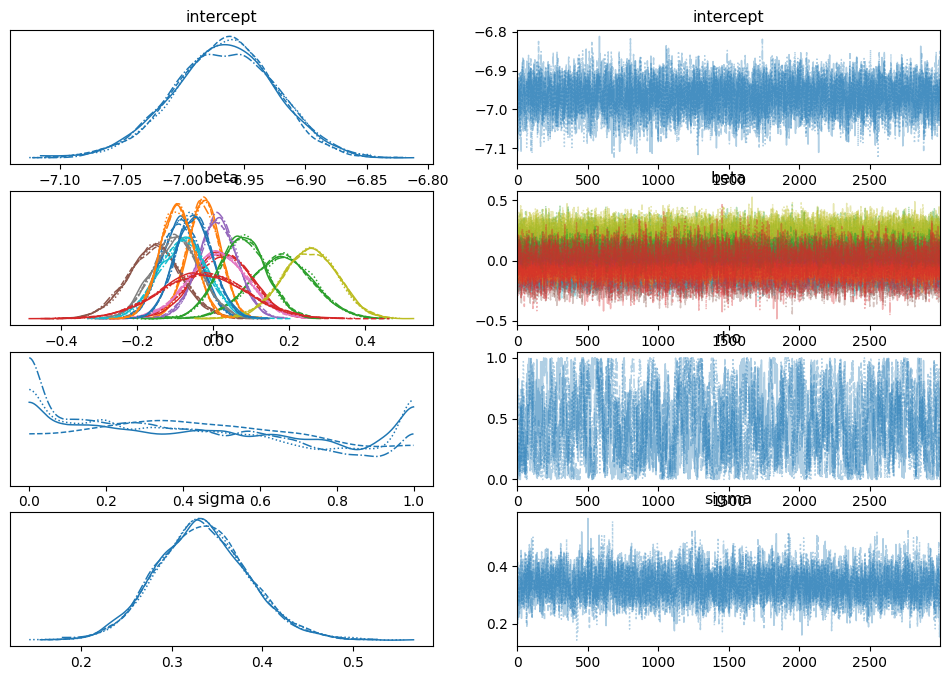

In [20]:
# Inspect MCMC mixing and convergence in the main model parameters.
az.plot_trace(idata_p, var_names=["intercept", "beta", "rho", "sigma"]);

In [21]:
# Identify parameters with R-hat above the selected diagnostic threshold.
summary_p = az.summary(idata_p)
summary_p[summary_p["r_hat"] > 1.01].sort_values("r_hat", ascending=False)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [22]:
# Report convergence and effective-sample-size diagnostics.
print("max r_hat:", summary_p["r_hat"].max())
print("n r_hat > 1.01:", (summary_p["r_hat"] > 1.01).sum())
print("n r_hat is NaN:", summary_p["r_hat"].isna().sum())

print("ess bulk:", summary_p["ess_bulk"].min())
print("ess tail:", summary_p["ess_tail"].min())

print("diverging:", idata_p.sample_stats["diverging"].sum().values)

max r_hat: 1.01
n r_hat > 1.01: 0
n r_hat is NaN: 0
ess bulk: 365.0
ess tail: 911.0
diverging: 0


In [23]:
# Summarize posterior parameters with 95% highest-density intervals.
az.summary(idata_p, var_names=["intercept", "beta", "rho", "sigma"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-6.966,0.042,-7.050,-6.886,0.001,0.000,4734.0,7503.0,1.00
beta[Proportion of men],-0.085,0.051,-0.183,0.018,0.001,0.000,5273.0,7576.0,1.00
beta[Proportion of residents aged 65 years or older],-0.025,0.043,-0.113,0.056,0.001,0.000,3320.0,6472.0,1.00
beta[Proportion of single-person households],0.181,0.082,0.025,0.347,0.001,0.001,3197.0,6559.0,1.00
beta[Proportion of households living in publicly rented housing],0.022,0.077,-0.132,0.166,0.001,0.001,4319.0,6644.0,1.00
beta[Proportion of foreign residents],0.012,0.052,-0.093,0.112,0.001,0.000,4877.0,7809.0,1.00
beta[Proportion of mother-child households],-0.153,0.071,-0.294,-0.010,0.001,0.001,3105.0,7726.0,1.00
beta[Unemployment rate],0.013,0.078,-0.145,0.163,0.001,0.001,6061.0,7842.0,1.00
beta[Proportion of short-term residents],-0.097,0.063,-0.220,0.024,0.001,0.001,4973.0,7505.0,1.00
beta[Less than high school education],0.253,0.073,0.115,0.402,0.001,0.001,6225.0,7456.0,1.00


In [24]:
# Generate posterior predictive counts for the fitted Poisson model.
with bym2_model_possion:
    idata_p_sa = pm.sample_posterior_predictive(idata_p, var_names=["y_i"], predictions=False, extend_inferencedata=True, random_seed=321)

Output()

In [25]:
# Save the fitted model and posterior predictive samples in NetCDF format.
idata_p_sa.to_netcdf("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p_sa.nc")

'/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p_sa.nc'

In [26]:
# Repeat MCMC estimation with a second random seed as a reproducibility check.
with bym2_model_possion:
    idata_p_2 = pm.sample(chains=4,
                      target_accept=0.95,
                      tune=3000,
                      draws=3000,
                      #nuts_sampler="numpyro",
                      random_seed=123)

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


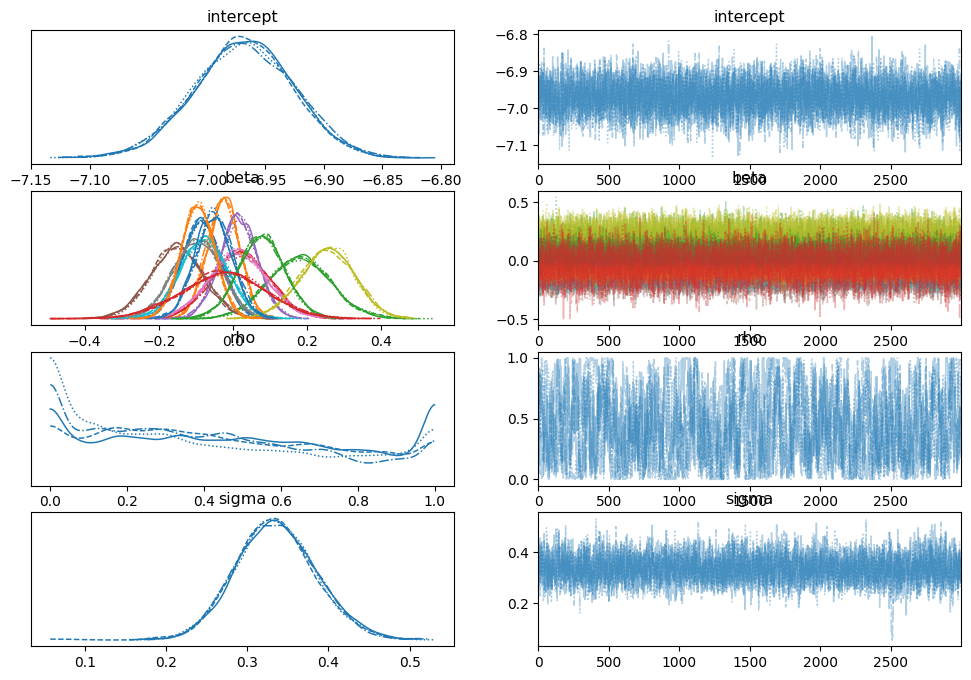

In [27]:
# Inspect posterior traces from the repeated fit.
az.plot_trace(idata_p_2, var_names=["intercept", "beta", "rho", "sigma"]);

In [28]:
# Check for elevated R-hat values in the repeated fit.
summary_p_2 = az.summary(idata_p_2)
summary_p_2[summary_p_2["r_hat"] > 1.01].sort_values("r_hat", ascending=False)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [29]:
# Summarize convergence and effective sample sizes for the repeated fit.
print("max r_hat:", summary_p_2["r_hat"].max())
print("n r_hat > 1.01:", (summary_p_2["r_hat"] > 1.01).sum())
print("n r_hat is NaN:", summary_p_2["r_hat"].isna().sum())

print("ess bulk:", summary_p_2["ess_bulk"].min())
print("ess tail:", summary_p_2["ess_tail"].min())

print("diverging:", idata_p_2.sample_stats["diverging"].sum().values)

max r_hat: 1.01
n r_hat > 1.01: 0
n r_hat is NaN: 0
ess bulk: 367.0
ess tail: 607.0
diverging: 0


In [30]:
# Inspect parameter summaries from the repeated fit.
az.summary(idata_p_2, var_names=["intercept", "beta", "rho", "sigma"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-6.969,0.042,-7.049,-6.884,0.001,0.000,5448.0,7422.0,1.00
beta[Proportion of men],-0.084,0.053,-0.188,0.017,0.001,0.001,3981.0,5887.0,1.00
beta[Proportion of residents aged 65 years or older],-0.026,0.043,-0.112,0.054,0.001,0.000,3829.0,7695.0,1.00
beta[Proportion of single-person households],0.179,0.084,0.016,0.350,0.002,0.001,3174.0,4724.0,1.00
beta[Proportion of households living in publicly rented housing],0.020,0.077,-0.134,0.167,0.001,0.001,4364.0,7329.0,1.00
beta[Proportion of foreign residents],0.014,0.051,-0.091,0.111,0.001,0.000,4446.0,7149.0,1.00
beta[Proportion of mother-child households],-0.151,0.072,-0.291,-0.009,0.001,0.001,4191.0,6994.0,1.00
beta[Unemployment rate],0.014,0.078,-0.140,0.164,0.001,0.001,5607.0,7593.0,1.00
beta[Proportion of short-term residents],-0.096,0.064,-0.221,0.030,0.001,0.001,5414.0,7675.0,1.00
beta[Less than high school education],0.253,0.073,0.104,0.391,0.001,0.001,5790.0,7544.0,1.00


In [31]:
# Generate posterior predictive counts from the repeated fit.
with bym2_model_possion:
    idata_p_2 = pm.sample_posterior_predictive(idata_p_2, var_names=["y_i"], predictions=False, extend_inferencedata=True, random_seed=123)

Output()

In [32]:
# Save the repeated fit and predictive samples to NetCDF.
idata_p_2.to_netcdf("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p_2.nc")

'/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p_2.nc'

In [33]:
# Calculate variance inflation factors (VIFs) as a multicollinearity diagnostic.
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = pd.DataFrame(X_cont, columns=covariate_cols)

vif_df = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_df.sort_values("VIF", ascending=False)

,variable,VIF
3,Proportion of households living in publicly re...,3.591471
2,Proportion of single-person households,3.479558
6,Unemployment rate,2.793708
9,Density of healthcare facilities (Log-transfor...,2.535658
5,Proportion of mother-child households,2.225674
12,Land prices (Log-transformed),2.222133
7,Proportion of short-term residents,1.864426
4,Proportion of foreign residents,1.813940
10,density of bus stops (Log-transformed),1.538406
0,Proportion of men,1.508982


In [34]:
# Inspect correlations among the predictors used in the sensitivity analysis.
X_df = pd.DataFrame(X, columns=model_cols)
correlation_matrix = X_df.corr()
display(correlation_matrix)

,Proportion of men,Proportion of residents aged 65 years or older,Proportion of single-person households,Proportion of households living in publicly rented housing,Proportion of foreign residents,Proportion of mother-child households,Unemployment rate,Proportion of short-term residents,Less than high school education,Density of healthcare facilities (Log-transformed),density of bus stops (Log-transformed),Density of railway stations (Log-transformed),Land prices (Log-transformed),Missing of land prices
Proportion of men,1.000000,0.143441,-0.182951,-0.221461,0.153150,-0.054063,-0.163052,-0.133710,0.158902,-0.316895,-0.246214,-0.139261,-0.322152,-0.056837
Proportion of residents aged 65 years or older,0.143441,1.000000,-0.213857,-0.008625,-0.052537,0.034254,0.061446,-0.252046,0.140529,-0.256973,-0.072732,-0.001246,-0.194853,0.083023
Proportion of single-person households,-0.182951,-0.213857,1.000000,-0.114926,0.392367,-0.281850,0.079986,0.587932,-0.323709,0.653319,0.286210,0.369281,0.587280,-0.074421
Proportion of households living in publicly rented housing,-0.221461,-0.008625,-0.114926,1.000000,0.300217,0.698409,0.718290,-0.120248,0.363642,-0.064299,0.213194,-0.026490,-0.101297,0.232074
Proportion of foreign residents,0.153150,-0.052537,0.392367,0.300217,1.000000,0.146281,0.431912,0.199329,0.033847,0.225052,0.279542,0.080787,0.056585,-0.021793
Proportion of mother-child households,-0.054063,0.034254,-0.281850,0.698409,0.146281,1.000000,0.507726,-0.237761,0.337167,-0.155938,0.162529,-0.111110,-0.212631,0.144221
Unemployment rate,-0.163052,0.061446,0.079986,0.718290,0.431912,0.507726,1.000000,-0.106676,0.236218,0.043798,0.217975,0.013117,-0.134338,0.198749
Proportion of short-term residents,-0.133710,-0.252046,0.587932,-0.120248,0.199329,-0.237761,-0.106676,1.000000,-0.259515,0.468200,0.241392,0.257937,0.241129,-0.250193
Less than high school education,0.158902,0.140529,-0.323709,0.363642,0.033847,0.337167,0.236218,-0.259515,1.000000,-0.431219,-0.213970,-0.202001,-0.312682,0.394211
Density of healthcare facilities (Log-transformed),-0.316895,-0.256973,0.653319,-0.064299,0.225052,-0.155938,0.043798,0.468200,-0.431219,1.000000,0.465839,0.387099,0.566003,-0.169705
